In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

import essrs

In [2]:
N_MIX = 2
THETA = np.array([0.5])
MU = np.array([-3.0, 3.0])
SIGMA = np.array([0.5, 0.5])

In [3]:
N_SAMPLES: int = 10000
N_WALKERS: int = 1000
N_PARAMETERS: int = 1
N_BURN_IN: int = 1000
N_THREADS: int = 1
N_THINNING_PER_SAMPLE: int = None

In [4]:
burn_move = essrs.moves.hybrid_ddc_move(one_in_n=10)
sampler_move = essrs.moves.differential_move()
config = essrs.EnsembleConfig(
    n_samples=N_SAMPLES,
    n_walkers=N_WALKERS,
    n_parameters=N_PARAMETERS,
    n_burn_in=N_BURN_IN,
    n_threads=N_THREADS,
    n_thinning_per_sample=N_THINNING_PER_SAMPLE
)

In [5]:
ics = np.random.uniform(low=-5, high=5, size=(N_WALKERS, N_PARAMETERS))

In [6]:
model = essrs.model.toy.dyn_fdata_ncomp_mm(
    np.array([0.5]),
    [
        essrs.model.toy.normal_1d(MU[0], SIGMA[0]),
        essrs.model.toy.normal_1d(MU[1], SIGMA[1])
    ]
)

start = time.perf_counter()
fit_dyn, ll = essrs.run_mcmc(
    log_likelihood=model,
    config=config,
    burn_in_move=burn_move,
    sampling_move=sampler_move,
    initial_conditions=ics
)
elapsed = time.perf_counter() - start
print(f"Dynamic dispatch :: {elapsed:.3f} seconds")

Dynamic dispatch :: 7.145 seconds


In [7]:
model = essrs.model.toy.normal_1d_mix(N_MIX, THETA, MU, SIGMA)

start = time.perf_counter()
fit_stat, ll = essrs.run_mcmc(
    log_likelihood=model,
    config=config,
    burn_in_move=burn_move,
    sampling_move=sampler_move,
    initial_conditions=ics
)
elapsed = time.perf_counter() - start
print(f"Static dispatch :: {elapsed:.3f} seconds")


Static dispatch :: 6.338 seconds


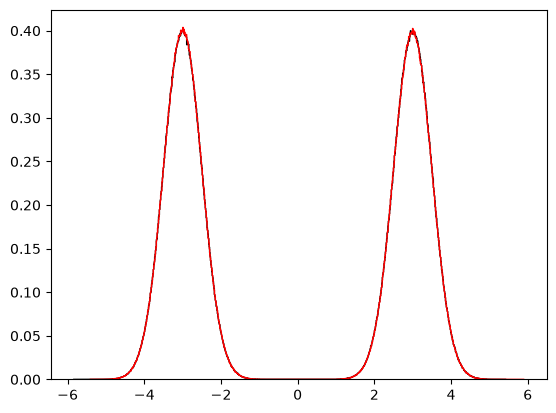

In [8]:
plt.figure()
plt.hist(fit_dyn.ravel(), bins=1000, density=True, histtype="step", color="k")
plt.hist(fit_stat.ravel(), bins=1000, density=True, histtype="step", color="r")
plt.show()